In [65]:
%matplotlib inline

# Solution 1 — Build a FODO ring

**Build an electron storage ring from identical FODO cells**. 

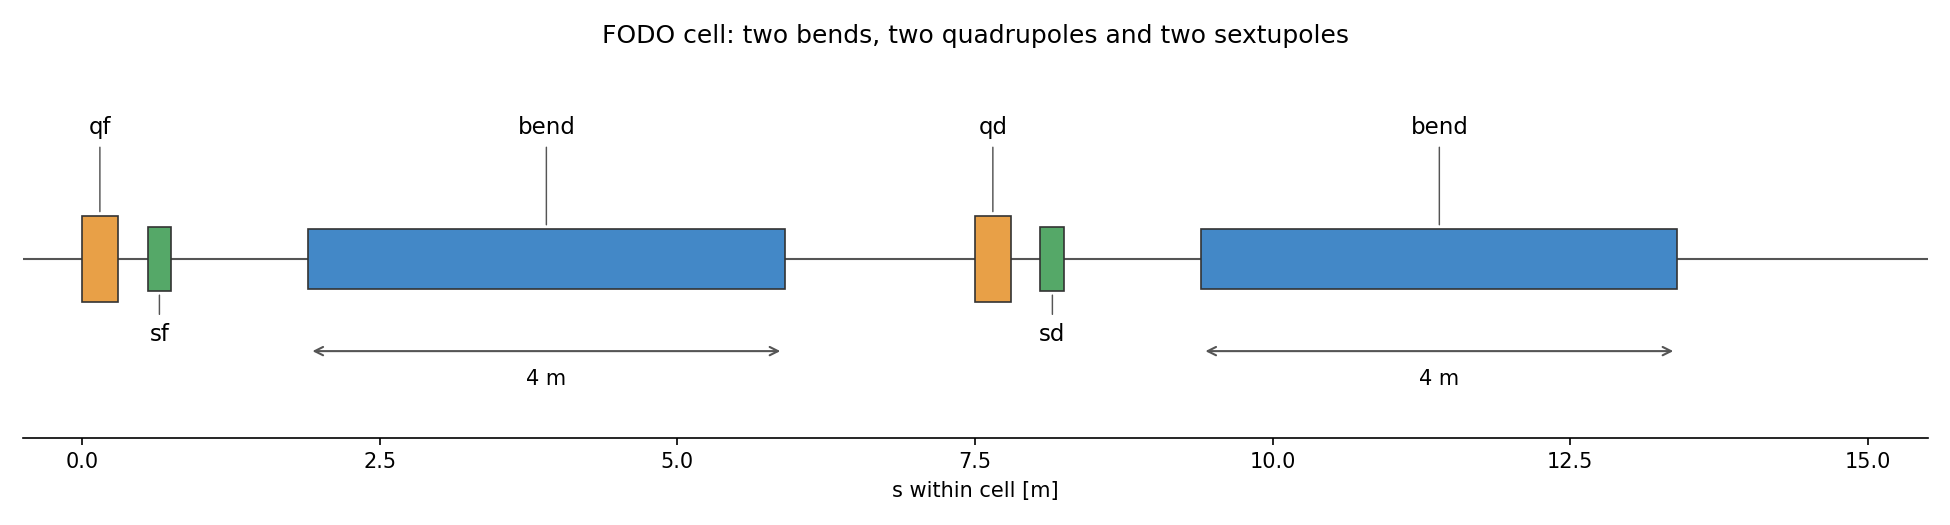

Indicative cell layout.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical FODO cells | 16 |
| Phase advance per cell (horizontal / vertical) | 91° / 92° |
| Dipole type | Sector bend (`xt.Bend`) |
| Dipole length | 4.0 m |
| Quadrupole length | 0.30 m |
| Sextupole length | 0.20 m |
| Ring chromaticity | 0.5 / 0.5 |

### Imports

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

### Create xsuite environment

In [67]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

### Geometry parameters

In [68]:
env['angle_bend'] = 2 * np.pi / 2 / 16

env['l_cell'] = 240. / 16.
env['l_bend'] = 4.
env['l_quad'] = 0.3
env['l_sext'] = 0.2

### Magnet strengths (initialized to zero)

In [69]:
env['kqf'] = 0.0
env['kqd'] = 0.0

env['ksf'] = 0.0
env['ksd'] = 0.0

### Define the magnets and build the cell

In [70]:
env.new('bend', xt.Bend, length='l_bend', angle='angle_bend')

env.new('qf', xt.Quadrupole, length='l_quad', k1='kqf')
env.new('qd', xt.Quadrupole, length='l_quad', k1='kqd')

env.new('sf', xt.Sextupole, length='l_sext', k2='ksf')
env.new('sd', xt.Sextupole, length='l_sext', k2='ksd')

'sd'

### Define cell

In [71]:
cell = env.new_line(length=env['l_cell'], components=[
    # Quadrupoles
    env.place('qf', anchor='start', at=0),
    env.place('qd', anchor='start', at='l_cell / 2'),

    # Bends
    env.place('bend', anchor='center', at='l_cell / 4'),
    env.place('bend', anchor='center', at='l_cell * 3 / 4'),

    # Sextupoles
    env.place('sf', anchor='start', at=0.2, from_='qf@end'),
    env.place('sd', anchor='start', at=0.2, from_='qd@end') 
])

### Survey the cell

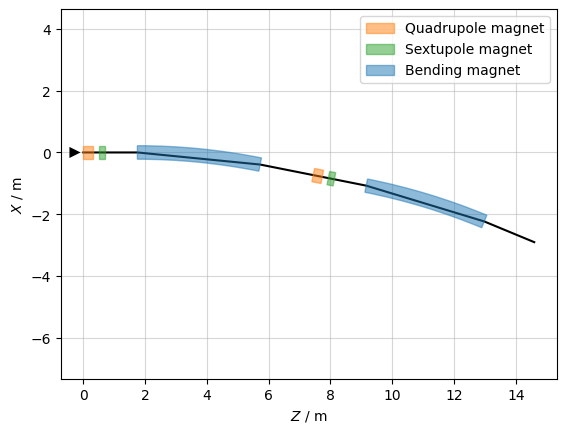

In [72]:
sv_cell = cell.survey()
sv_cell.plot()

### Set weak quadrupole strengths and compute initial twiss

In [73]:
env['kqf'] = 0.10
env['kqd'] = -0.10

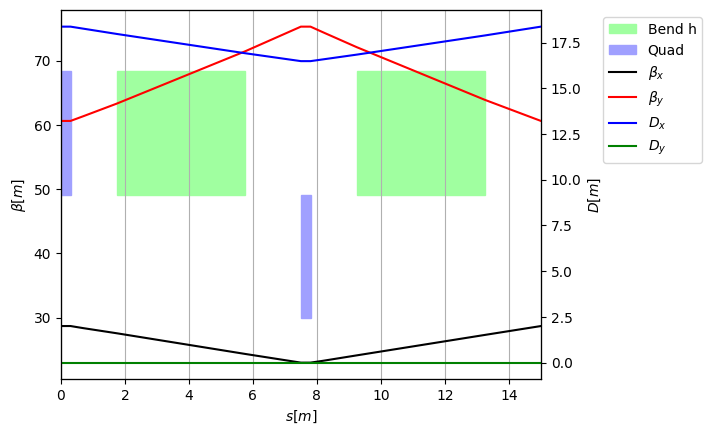

In [74]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Match the cell phase advances

In [75]:
# Optimize cell periodic solution to obtain desired phase advance
opt_cell = cell.match(
    solve=False,
    method='4d',
    vary=[
        xt.Vary('kqf', limits=(0, 10), step=1e-3),
        xt.Vary('kqd', limits=(-10, 0), step=1e-3),
    ],
    targets=[
        xt.TargetSet(qx=91./360, qy=92./360)
    ],
)

In [76]:
# Before optimization
opt_cell.target_status()

Target status:               alty = 2.7215e+00              
id state tag tol_met       residue   current_val    target_val description                             
0  ON    qx    False     -0.159997     0.0927803      0.252778 'qx', val=0.252778, tol=1e-09, weight=10
1  ON    qy    False     -0.220153     0.0354021      0.255556 'qy', val=0.255556, tol=1e-09, weight=10


In [77]:
# Optimize
opt_cell.run_jacobian(30)

                                             
Optimize - start penalty: 2.722                             
Matching: model call n. 23 penalty = 8.7496e-10              
Optimize - end penalty:  8.74958e-10                            


In [79]:
# After optimization
opt_cell.target_status()
opt_cell.vary_status()

Target status:               nalty = 8.7496e-10              
id state tag tol_met       residue   current_val    target_val description                             
0  ON    qx     True   2.08987e-11      0.252778      0.252778 'qx', val=0.252778, tol=1e-09, weight=10
1  ON    qy     True  -8.49633e-11      0.255556      0.255556 'qy', val=0.255556, tol=1e-09, weight=10
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqf            0      0.612709          10           0.1         0.001             1
1  ON        OK  kqd          -10     -0.642091           0          -0.1         0.001             1


### Inspect the matched cell optics

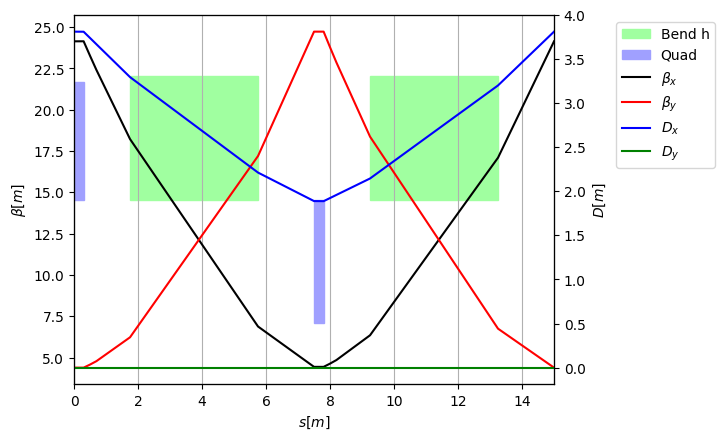

In [80]:
tw_cell = cell.twiss4d()
tw_cell.plot()

### Assemble the ring

In [81]:
n_cells = 16
ring = n_cells * cell

### Give unique names to all elements

In [82]:
ring.replace_all_repeated_elements()

### Survey

In [83]:
sv = ring.survey()

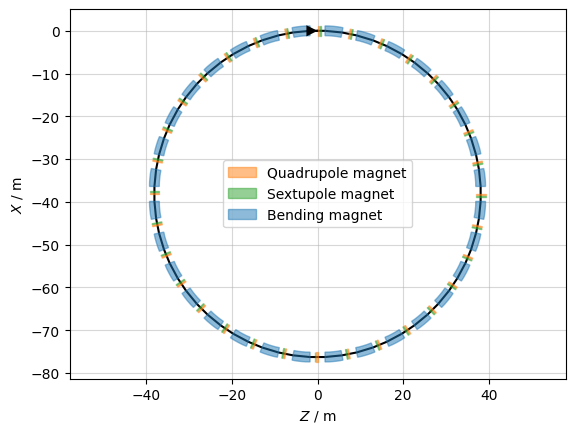

In [84]:
sv.plot()

### Full-ring optics

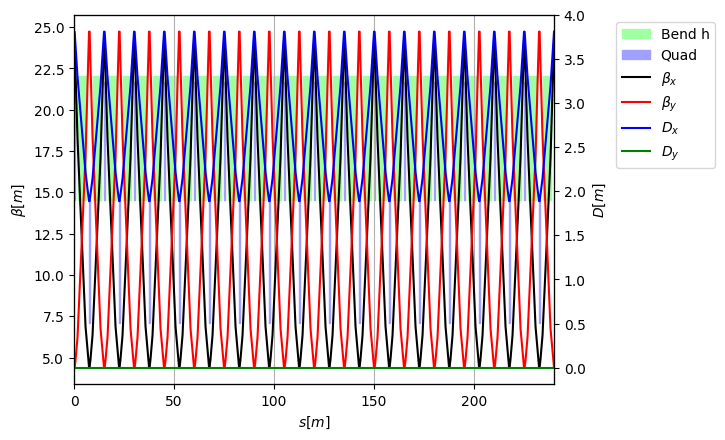

In [85]:
tw_ring = ring.twiss4d()
tw_ring.plot()

In [86]:
# Inspect tunes
tw_ring.qx, tw_ring.qy

(4.044444444787956, 4.08888888752955)

### Correct the chromaticities

In [87]:
opt_chrom = ring.match(
    solve=False,
    method='4d',
    vary=[
        xt.Vary('ksf', limits=(0, 10), step=1e-3),
        xt.Vary('ksd', limits=(-10, 0), step=1e-3),
    ],
    targets=xt.TargetSet(dqx=0.5, dqy=0.5, tol=0.001),
)

In [88]:
opt_chrom.target_status()

Target status:               alty = 7.0281e+00              
id state tag tol_met       residue   current_val    target_val description                        
0  ON    dqx   False      -4.67854      -4.17854           0.5 'dqx', val=0.5, tol=0.001, weight=1
1  ON    dqy   False      -5.24451      -4.74451           0.5 'dqy', val=0.5, tol=0.001, weight=1


In [90]:
opt_chrom.run_jacobian(20)

                                             
Optimize - start penalty: 7.028                             
Matching: model call n. 8 penalty = 4.7789e-04              
Optimize - end penalty:  0.000477887                            


In [ ]:
opt_chrom.target_status()
opt_chrom.vary_status()

### Final tunes and chromaticities

In [ ]:
tw_ring = ring.twiss4d()
print(f'Tunes: {tw_ring.qx:.6f} / {tw_ring.qy:.6f}')
print(f'Chromaticities: {tw_ring.dqx:.6f} / {tw_ring.dqy:.6f}')

### Save the ring

In [92]:
ring.to_json('ring_fodo.json')